In [1]:
# Completa: define tu diccionario de lugares con coordenadas reales
lugares = {
    "Wanchaq (Casa)": (-13.532021, -71.956405),
    "UNSAAC (Perayoc)":          (-13.521801427024677, -71.95833925049237),
    "Plaza de Armas":            (-13.5170, -71.9785),
    "Sacsayhuaman":              (-13.5075, -71.9817),
}

for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")
    

Wanchaq (Casa): lat=-13.532021, lon=-71.956405
UNSAAC (Perayoc): lat=-13.521801427024677, lon=-71.95833925049237
Plaza de Armas: lat=-13.517, lon=-71.9785
Sacsayhuaman: lat=-13.5075, lon=-71.9817


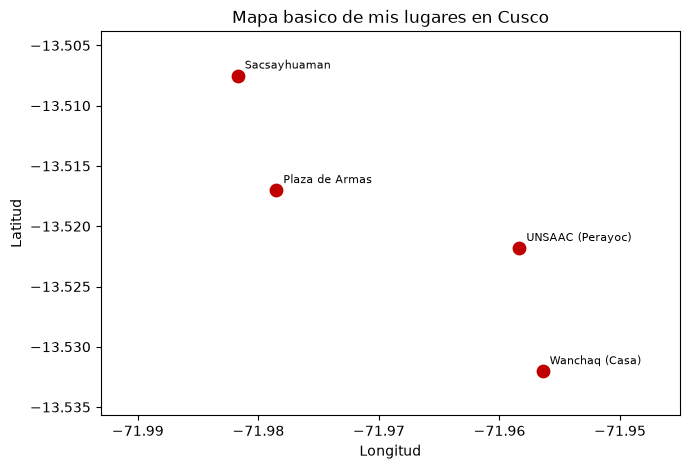

Mapa guardado como mapa_basico.png


In [2]:
import matplotlib.pyplot as plt

# Completa: extrae lats y lons, y grafica
lats = [v[0] for v in lugares.values()]
lons = [v[1] for v in lugares.values()]
nombres = list(lugares.keys())

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(lons, lats, c="#C00000", s=80)

for nombre, lon, lat in zip(nombres, lons, lats):
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Mapa basico de mis lugares en Cusco")
ax.set_aspect("equal")
ax.margins(x=0.45, y=0.15)
plt.tight_layout()
plt.savefig("mapa_basico.png", dpi=150)
plt.show()
print("Mapa guardado como mapa_basico.png")

In [9]:
import math

# Completa: define la funcion distancia_haversine
def distancia_haversine(lat1, lon1, lat2, lon2):
    """Distancia en km entre dos coordenadas geograficas (formula de Haversine)."""
    R = 6371.0  # radio promedio de la Tierra en km
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    return R * c

In [8]:
# Completa: calcula las distancias desde tu primer lugar
primer_lugar = "Wanchaq (Casa)"
lat0, lon0 = lugares[primer_lugar]

for nombre, (lat, lon) in lugares.items():
    if nombre == primer_lugar:
        continue
    d = distancia_haversine(lat0, lon0, lat, lon)
    print(f"{primer_lugar} -> {nombre}: {d:.4f} km")

Wanchaq (Casa) -> UNSAAC (Perayoc): 1.1554 km
Wanchaq (Casa) -> Plaza de Armas: 2.9147 km
Wanchaq (Casa) -> Sacsayhuaman: 3.8618 km


In [10]:
from itertools import combinations

# Completa: identifica el par mas cercano y el mas lejano
pares = []
for (n1, (lat1, lon1)), (n2, (lat2, lon2)) in combinations(lugares.items(), 2):
    d = distancia_haversine(lat1, lon1, lat2, lon2)
    pares.append((d, n1, n2))
    print(f"{n1} <-> {n2}: {d:.4f} km")

mas_cercano = min(pares)
mas_lejano = max(pares)

print(f"\nPar mas cercano: {mas_cercano[1]} y {mas_cercano[2]} ({mas_cercano[0]:.4f} km)")
print(f"Par mas lejano:  {mas_lejano[1]} y {mas_lejano[2]} ({mas_lejano[0]:.4f} km)")

Wanchaq (Casa) <-> UNSAAC (Perayoc): 1.1554 km
Wanchaq (Casa) <-> Plaza de Armas: 2.9147 km
Wanchaq (Casa) <-> Sacsayhuaman: 3.8618 km
UNSAAC (Perayoc) <-> Plaza de Armas: 2.2441 km
UNSAAC (Perayoc) <-> Sacsayhuaman: 2.9846 km
Plaza de Armas <-> Sacsayhuaman: 1.1116 km

Par mas cercano: Plaza de Armas y Sacsayhuaman (1.1116 km)
Par mas lejano:  Wanchaq (Casa) y Sacsayhuaman (3.8618 km)


In [11]:
import json

# Completa: construye la lista de features y el GeoJSON completo
features = []
for nombre, (lat, lon) in lugares.items():
    features.append({
        "type": "Feature",
        "properties": {"nombre": nombre},
        "geometry": {
            "type": "Point",
            "coordinates": [lon, lat]  # orden obligatorio en GeoJSON: [longitud, latitud]
        }
    })

geojson_mio = {"type": "FeatureCollection", "features": features}

# Completa: guarda el archivo
with open("mis_lugares.geojson", "w", encoding="utf-8") as f:
    json.dump(geojson_mio, f, indent=2, ensure_ascii=False)

print("Archivo guardado con", len(features), "features")

Archivo guardado con 4 features


In [12]:
# Completa: reabre y verifica
with open("mis_lugares.geojson", "r", encoding="utf-8") as f:
    data = json.load(f)

print("Cantidad de features:", len(data["features"]))
print("Primer lugar:", data["features"][0]["properties"]["nombre"])
print("Sus coordenadas [lon, lat]:", data["features"][0]["geometry"]["coordinates"])

Cantidad de features: 4
Primer lugar: Wanchaq (Casa)
Sus coordenadas [lon, lat]: [-71.956405, -13.532021]
